# BFGSはHessianを計算せずに何を近似しているのか

## 概要

BFGSは、点の移動量と勾配の変化量を使って、Hessianまたはその逆行列を近似する準Newton法である。二階微分の各成分を計算する代わりに、移動した方向で観測した曲率を行列に反映する。

この記事では、セカント条件とBFGS更新式を導き、Pythonで更新を実装する。二次関数とRosenbrock関数を使い、解の収束、行列の近似誤差、セカント条件の残差を別々に確認する。

### 実行環境

仮想環境とJupyterカーネルの表示名は `wa-src(3.14.6)`、Pythonは `3.14.6` である。使用ライブラリとOSは次の出力に示す。Notebookのあるフォルダーを作業ディレクトリとして、上から順に実行する。

小数の表示は有効数字3桁とし、計算途中では丸めない。図は `103_nb_files` にSVG形式で保存し、出力欄にも埋め込む。

In [1]:
import platform
import sys
from importlib.metadata import version
from pathlib import Path
from pprint import pprint

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Latex, Math, SVG, display
from matplotlib.ticker import FuncFormatter, MaxNLocator, NullFormatter
from matplotlib_inline.backend_inline import set_matplotlib_formats
from scipy.optimize import line_search, minimize

%matplotlib inline
set_matplotlib_formats("svg")

assert platform.python_version() == "3.14.6"
assert sys.prefix != sys.base_prefix
print("環境: wa-src(3.14.6)")
print("Python:", platform.python_version())
print("OS:", platform.platform())
print("実行ファイル:", sys.executable)
pprint({name: version(name) for name in ("numpy", "scipy", "matplotlib")})

np.set_printoptions(formatter={"float_kind": lambda v: f"{v:#.3g}"})
plt.rcParams.update({"font.size": 11, "svg.fonttype": "none"})
figure_dir = Path("103_nb_files")
figure_dir.mkdir(exist_ok=True)


def save_figure(fig, name):
    """小数の目盛りを3桁にし、SVGを保存して出力欄に表示する。"""
    for ax in fig.axes:
        for axis in (ax.xaxis, ax.yaxis):
            axis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:#.3g}"))
            axis.set_minor_formatter(NullFormatter())
        if ax.get_xlabel() == "Iteration":
            ax.xaxis.set_major_locator(MaxNLocator(integer=True))
            ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}"))
        ax.grid(alpha=0.250)
        if ax.get_legend_handles_labels()[0]:
            ax.legend()
    path = figure_dir / name
    fig.savefig(path, format="svg", bbox_inches="tight")
    plt.close(fig)
    display(SVG(filename=str(path)))

環境: wa-src(3.14.6)
Python: 3.14.6
OS: macOS-26.5.2-arm64-arm-64bit-Mach-O
実行ファイル: /Users/hiroshi/private/wa_src/.venv/bin/python
{'matplotlib': '3.11.2', 'numpy': '2.5.4', 'scipy': '1.18.1'}


## 1. 近似するのは二次モデルの曲率である

$f:\mathbb{R}^n\to\mathbb{R}$を最小化する。$f$は2回連続微分可能とし、勾配を$\mathbf{g}_k=\nabla f(\mathbf{x}_k)$、真のHessianを$\mathbf{G}_k=\nabla^2f(\mathbf{x}_k)$と書く。Taylor展開は、

$$
f(\mathbf{x}_k+\mathbf{p})
=f(\mathbf{x}_k)+\mathbf{g}_k^\top\mathbf{p}
+\frac12\mathbf{p}^\top\mathbf{G}_k\mathbf{p}
+o(\|\mathbf{p}\|^2)
$$

である。$\mathbf{G}_k$を対称正定値行列$\mathbf{B}_k$で置き換え、二次モデル$q_k$を作る。

$$
\begin{aligned}
q_k(\mathbf{p})&=f(\mathbf{x}_k)+\mathbf{g}_k^\top\mathbf{p}
+\frac12\mathbf{p}^\top\mathbf{B}_k\mathbf{p},\\
\nabla_{\mathbf{p}}q_k(\mathbf{p})&=\mathbf{g}_k+\mathbf{B}_k\mathbf{p},\\
\nabla_{\mathbf{p}}q_k(\mathbf{p}_k)=\mathbf{0}
&\Longrightarrow \mathbf{B}_k\mathbf{p}_k=-\mathbf{g}_k,\\
\mathbf{p}_k&=-\mathbf{H}_k\mathbf{g}_k,
\qquad \mathbf{H}_k=\mathbf{B}_k^{-1},\\
\mathbf{x}_{k+1}&=\mathbf{x}_k+\alpha_k\mathbf{p}_k.
\end{aligned}
$$

$\mathbf{B}_k$はHessianの近似、$\mathbf{H}_k$は逆Hessianの近似である。ここでの$\mathbf{H}$はHessianそのものではない。$\mathbf{G}_k$が不定値の場所では、正定値の$\mathbf{B}_k$で負の曲率まで再現することはできない。

## 2. 勾配の差から分かること

移動量と勾配差を、

$$
\mathbf{s}_k=\mathbf{x}_{k+1}-\mathbf{x}_k,
\qquad
\mathbf{y}_k=\mathbf{g}_{k+1}-\mathbf{g}_k
$$

と定める。線分上の勾配を$t$で微分し、積分すると次の関係が得られる。

$$
\begin{aligned}
\frac{d}{dt}\nabla f(\mathbf{x}_k+t\mathbf{s}_k)
&=\nabla^2f(\mathbf{x}_k+t\mathbf{s}_k)\mathbf{s}_k,\\
\mathbf{y}_k
&=\int_0^1\nabla^2f(\mathbf{x}_k+t\mathbf{s}_k)\mathbf{s}_k\,dt,\\
\overline{\mathbf{G}}_k
&=\int_0^1\nabla^2f(\mathbf{x}_k+t\mathbf{s}_k)\,dt,\\
\mathbf{y}_k&=\overline{\mathbf{G}}_k\mathbf{s}_k.
\end{aligned}
$$

観測したのは、線分上の平均Hessianが$\mathbf{s}_k$に作用した結果である。一般には$\mathbf{y}_k=\mathbf{G}_k\mathbf{s}_k$ではない。この関係を近似行列にも課すのがセカント条件である。

$$
\boxed{\mathbf{B}_{k+1}\mathbf{s}_k=\mathbf{y}_k}
\qquad\Longleftrightarrow\qquad
\boxed{\mathbf{H}_{k+1}\mathbf{y}_k=\mathbf{s}_k}
$$

条件は$n$本の方程式である。対称行列の未知成分は$n(n+1)/2$個なので、$n>1$ではこれだけで行列全体は決まらない。私は「Hessianを推定する」という説明に、この方向の情報しか観測していない点を補うと理解しやすいと感じる。

1変数の$f(x)=x^4/4+x^2/2$で、$x_0=0$から$x_1=1$へ移動する場合を考える。

$$
\begin{aligned}
f'(x)&=x^3+x,\qquad f''(x)=3x^2+1,\\
\frac{y}{s}&=\frac{f'(1)-f'(0)}{1-0}=2,\\
\int_0^1f''(t)\,dt&=[t^3+t]_0^1=2,\\
f''(0)&=1,\qquad f''(1)=4.
\end{aligned}
$$

図1の割線の傾きは2であり、両端の二階微分とは異なる。

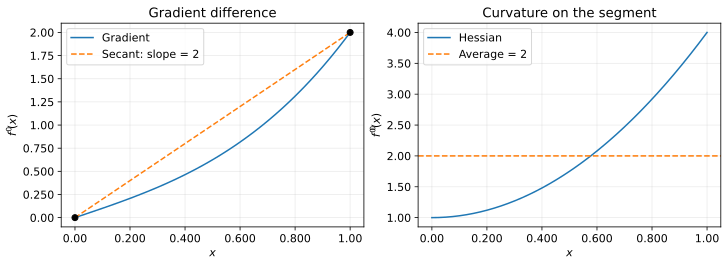

In [2]:
x = np.linspace(0, 1, 200)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.60), layout="constrained")
axes[0].plot(x, x**3 + x, label="Gradient")
axes[0].plot(x, 2*x, "--", label="Secant: slope = 2")
axes[0].scatter([0, 1], [0, 2], color="black", zorder=3)
axes[0].set(xlabel="$x$", ylabel="$f'(x)$", title="Gradient difference")
axes[1].plot(x, 3*x**2 + 1, label="Hessian")
axes[1].axhline(2, color="tab:orange", linestyle="--", label="Average = 2")
axes[1].set(xlabel="$x$", ylabel="$f''(x)$", title="Curvature on the segment")
save_figure(fig, "01_secant.svg")

## 3. BFGS更新式を作る

添字$k$を省き、更新後を$+$で表す。対称性を保つ補正として、次の二つの外積を選ぶ。

$$
\mathbf{B}_{+}=\mathbf{B}
+a\mathbf{y}\mathbf{y}^\top
+b(\mathbf{B}\mathbf{s})(\mathbf{B}\mathbf{s})^\top.
$$

右から$\mathbf{s}$を掛け、係数をまとめる。

$$
\begin{aligned}
\mathbf{B}_{+}\mathbf{s}
&=\mathbf{B}\mathbf{s}
+a\mathbf{y}(\mathbf{y}^\top\mathbf{s})
+b\mathbf{B}\mathbf{s}(\mathbf{s}^\top\mathbf{B}\mathbf{s})\\
&=(1+b\mathbf{s}^\top\mathbf{B}\mathbf{s})\mathbf{B}\mathbf{s}
+a(\mathbf{s}^\top\mathbf{y})\mathbf{y}.
\end{aligned}
$$

$\mathbf{B}\mathbf{s}$の係数を0、$\mathbf{y}$の係数を1にすればよい。

$$
\begin{aligned}
1+b\mathbf{s}^\top\mathbf{B}\mathbf{s}=0
&\Longrightarrow b=-\frac{1}{\mathbf{s}^\top\mathbf{B}\mathbf{s}},\\
a\mathbf{s}^\top\mathbf{y}=1
&\Longrightarrow a=\frac{1}{\mathbf{s}^\top\mathbf{y}},\\
\mathbf{B}_{+}
&=\mathbf{B}
-\frac{\mathbf{B}\mathbf{s}\mathbf{s}^\top\mathbf{B}}
{\mathbf{s}^\top\mathbf{B}\mathbf{s}}
+\frac{\mathbf{y}\mathbf{y}^\top}{\mathbf{s}^\top\mathbf{y}},\\
\mathbf{B}_{+}\mathbf{s}
&=\mathbf{B}\mathbf{s}-\mathbf{B}\mathbf{s}+\mathbf{y}=\mathbf{y}.
\end{aligned}
$$

これがHessian側のBFGS更新である。二つの階数1の行列を加減するので、差の階数は高々2である。セカント条件から唯一の更新が決まるわけではなく、上の補正形を選んだ結果である。

### 逆行列を直接更新する

$\rho=1/(\mathbf{s}^\top\mathbf{y})$とすると、逆行列側の等価な式は、

$$
\mathbf{H}_{+}
=(\mathbf{I}-\rho\mathbf{s}\mathbf{y}^\top)
\mathbf{H}
(\mathbf{I}-\rho\mathbf{y}\mathbf{s}^\top)
+\rho\mathbf{s}\mathbf{s}^\top
$$

である。逆行列の関係は$\mathbf{B}_{+}\mathbf{H}_{+}=\mathbf{I}$で確認できる。セカント条件も直接確認できる。

$$
\begin{aligned}
(\mathbf{I}-\rho\mathbf{y}\mathbf{s}^\top)\mathbf{y}
&=\mathbf{y}-\rho\mathbf{y}(\mathbf{s}^\top\mathbf{y})=\mathbf{0},\\
\mathbf{H}_{+}\mathbf{y}
&=\mathbf{0}+\rho\mathbf{s}(\mathbf{s}^\top\mathbf{y})=\mathbf{s}.
\end{aligned}
$$

実装では積を展開して、行列同士の積を避ける。

$$
\begin{aligned}
\mathbf{v}&=\mathbf{H}\mathbf{y},\\
\mathbf{H}_{+}
&=\mathbf{H}-\rho\mathbf{s}\mathbf{y}^\top\mathbf{H}
-\rho\mathbf{H}\mathbf{y}\mathbf{s}^\top
+\rho^2\mathbf{s}(\mathbf{y}^\top\mathbf{H}\mathbf{y})\mathbf{s}^\top
+\rho\mathbf{s}\mathbf{s}^\top\\
&=\mathbf{H}-\rho(\mathbf{s}\mathbf{v}^\top+\mathbf{v}\mathbf{s}^\top)
+\rho(1+\rho\mathbf{y}^\top\mathbf{v})\mathbf{s}\mathbf{s}^\top.
\end{aligned}
$$

行列の保存と更新は$O(n^2)$である。毎回の逆行列計算は不要である。以下では丸め誤差への対策として、$\mathbf{s}^\top\mathbf{y}$が$1.00\times10^{-12}\|\mathbf{s}\|\|\mathbf{y}\|$以下なら更新を省略する。このしきい値は実装上の選択である。

In [3]:
def inverse_bfgs(H, s, y):
    """逆Hessian近似を更新する。曲率が小さい場合は前の行列を返す。"""
    sy = s @ y
    if sy <= 1.00e-12 * np.linalg.norm(s) * np.linalg.norm(y):
        return H.copy(), False
    rho = 1 / sy
    v = H @ y
    updated = H + rho * (1 + rho * (y @ v)) * np.outer(s, s)
    updated -= rho * (np.outer(s, v) + np.outer(v, s))
    # 浮動小数点演算による非対称成分だけを取り除く。
    return (updated + updated.T) / 2, True


display(Latex(r"\(\displaystyle\boxed{\mathbf{p}_k=-\mathbf{H}_k\mathbf{g}_k,"
              r"\quad \mathbf{H}_{k+1}\mathbf{y}_k=\mathbf{s}_k}\)"))

<IPython.core.display.Latex object>

## 4. 正定値性と直線探索

$\mathbf{H}\succ0$かつ$\mathbf{s}^\top\mathbf{y}>0$なら、更新後も正定値である。$\mathbf{V}=\mathbf{I}-\rho\mathbf{s}\mathbf{y}^\top$とすると、任意の$\mathbf{z}\ne\mathbf{0}$について、

$$
\mathbf{z}^\top\mathbf{H}_{+}\mathbf{z}
=(\mathbf{V}^\top\mathbf{z})^\top\mathbf{H}(\mathbf{V}^\top\mathbf{z})
+\rho(\mathbf{s}^\top\mathbf{z})^2.
$$

$\mathbf{s}^\top\mathbf{z}\ne0$なら第2項が正である。$\mathbf{s}^\top\mathbf{z}=0$なら$\mathbf{V}^\top\mathbf{z}=\mathbf{z}$なので第1項が正である。したがって、勾配が0でなければ探索方向は降下方向となる。

$$
\mathbf{g}_k^\top\mathbf{p}_k
=-\mathbf{g}_k^\top\mathbf{H}_k\mathbf{g}_k<0.
$$

ただし、降下方向でも歩幅$\alpha_k$が大き過ぎれば関数値は増える。直線探索で使うWolfe条件は、$0<c_1<c_2<1$として、

$$
\begin{aligned}
f(\mathbf{x}_k+\alpha_k\mathbf{p}_k)
&\le f(\mathbf{x}_k)+c_1\alpha_k\mathbf{g}_k^\top\mathbf{p}_k,\\
\mathbf{g}_{k+1}^\top\mathbf{p}_k
&\ge c_2\mathbf{g}_k^\top\mathbf{p}_k
\end{aligned}
$$

である。後者から、曲率条件が得られる。

$$
\begin{aligned}
\mathbf{s}_k^\top\mathbf{y}_k
&=\alpha_k\mathbf{p}_k^\top(\mathbf{g}_{k+1}-\mathbf{g}_k)\\
&\ge\alpha_k(c_2-1)\mathbf{g}_k^\top\mathbf{p}_k>0.
\end{aligned}
$$

SciPyの `line_search` は、2本目を$|\mathbf{g}_{k+1}^\top\mathbf{p}_k|\le c_2|\mathbf{g}_k^\top\mathbf{p}_k|$にした強Wolfe条件を使う。これは上の曲率条件も満たす。[SciPy公式資料](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.line_search.html)

以下は履歴を観察するための実装である。停止条件は$\|\mathbf{g}_k\|_2\le1.00\times10^{-8}$とする。直線探索の失敗は例外、反復上限は `success=False` として区別する。`step` は二次関数の実験だけで使う厳密な歩幅の関数である。

In [4]:
def bfgs_trace(f, grad, x0, step=None, tol=1.00e-8, maxiter=200):
    x = np.array(x0, dtype=float)
    H = np.eye(x.size)
    xs, matrices, residuals, accepted = [x.copy()], [H.copy()], [], []
    for _ in range(maxiter):
        g = grad(x)
        if np.linalg.norm(g) <= tol:
            break
        p = -H @ g
        if not np.all(np.isfinite(p)) or g @ p >= 0:
            raise RuntimeError("有限な降下方向が得られない")
        alpha = (step(x, g, p) if step else
                 line_search(f, grad, x, p, gfk=g,
                             c1=1.00e-4, c2=0.900, maxiter=30)[0])
        if alpha is None or not np.isfinite(alpha) or alpha <= 0:
            raise RuntimeError("直線探索が失敗した")
        new_x = x + alpha * p
        s, y = new_x - x, grad(new_x) - g
        H, used = inverse_bfgs(H, s, y)
        # 正規化したセカント残差。更新を省略した場合も記録する。
        residuals.append(np.linalg.norm(H @ y - s) / max(np.linalg.norm(s), 1.00e-300))
        accepted.append(used)
        x = new_x
        xs.append(x.copy())
        matrices.append(H.copy())
    return {"x": np.array(xs), "H": np.array(matrices),
            "residual": np.array(residuals), "updated": np.array(accepted),
            "success": bool(np.linalg.norm(grad(x)) <= tol)}

## 5. 二次関数で確かめる

次の正定値二次関数では、Hessianが一定である。

$$
\begin{aligned}
f(\mathbf{x})&=\frac12\mathbf{x}^\top\mathbf{A}\mathbf{x},
\qquad \mathbf{A}=\begin{bmatrix}10&9\\9&10\end{bmatrix},\\
\nabla f(\mathbf{x})&=\mathbf{A}\mathbf{x},
\qquad \nabla^2 f(\mathbf{x})=\mathbf{A},\\
\mathbf{y}_k&=\mathbf{A}(\mathbf{x}_{k+1}-\mathbf{x}_k)=\mathbf{A}\mathbf{s}_k.
\end{aligned}
$$

初期点は$\mathbf{x}_0=(2,-1)^\top$、$\mathbf{H}_0=\mathbf{I}$とする。この実験では各方向の最小点を厳密に求める。

$$
\begin{aligned}
\phi(\alpha)&=f(\mathbf{x}+\alpha\mathbf{p}),\\
\phi'(\alpha)&=\mathbf{p}^\top\mathbf{A}\mathbf{x}
+\alpha\mathbf{p}^\top\mathbf{A}\mathbf{p},\\
\phi'(\alpha)=0&\Longrightarrow
\alpha=-\frac{\mathbf{g}^\top\mathbf{p}}{\mathbf{p}^\top\mathbf{A}\mathbf{p}}.
\end{aligned}
$$

$\mathbf{A}$を使う歩幅は、この既知の二次関数だけの比較用である。一般の関数では前節の直線探索を使う。最急降下法は$\mathbf{p}=-\mathbf{g}$、Newton法は$\mathbf{A}\mathbf{p}=-\mathbf{g}$を解く。図2は移動経路、図3は勾配ノルムと逆Hessianの相対誤差である。

{'BFGS': {'gradient_norm': '3.30e-15', 'iterations': 2},
 'Newton': {'gradient_norm': '1.49e-15', 'iterations': 1},
 'Steepest descent': {'gradient_norm': '4.58e-09', 'iterations': 33}}


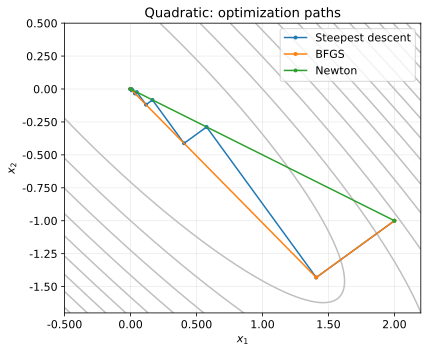

In [5]:
A = np.array([[10, 9], [9, 10]], dtype=float)
x0 = np.array([2, -1], dtype=float)


def quadratic(x):
    return (x @ A @ x) / 2


def quadratic_grad(x):
    return A @ x


def exact_step(x, g, p):
    return -(g @ p) / (p @ A @ p)


quad = bfgs_trace(quadratic, quadratic_grad, x0, step=exact_step)
gd = [x0.copy()]
for _ in range(300):
    g = quadratic_grad(gd[-1])
    if np.linalg.norm(g) <= 1.00e-8:
        break
    p = -g
    gd.append(gd[-1] + exact_step(gd[-1], g, p) * p)

# 比較用のNewton法では、真のHessianを使って方向を計算する。
newton = np.array([x0, x0 - np.linalg.solve(A, quadratic_grad(x0))])
paths = {"Steepest descent": np.array(gd), "BFGS": quad["x"], "Newton": newton}
pprint({name: {"iterations": len(path) - 1,
               "gradient_norm": f"{np.linalg.norm(A @ path[-1]):#.3g}"}
        for name, path in paths.items()})

u, v = np.meshgrid(np.linspace(-0.500, 2.20, 200), np.linspace(-1.70, 0.500, 200))
fig, ax = plt.subplots(figsize=(6.80, 4.80), layout="constrained")
ax.contour(u, v, 5*u**2 + 9*u*v + 5*v**2, levels=15, colors="0.750")
for name, path in paths.items():
    ax.plot(path[:, 0], path[:, 1], "o-", markersize=3, label=name)
ax.set(xlabel="$x_1$", ylabel="$x_2$", title="Quadratic: optimization paths", aspect="equal")
save_figure(fig, "02_quadratic_path.svg")

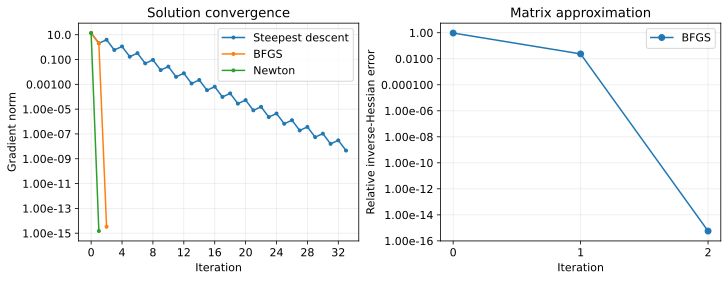

最後の逆Hessian近似:
array([[0.526, -0.474],
       [-0.474, 0.526]])
比較する真の逆行列:
array([[0.526, -0.474],
       [-0.474, 0.526]])


In [6]:
true_inverse = np.linalg.solve(A, np.eye(2))
matrix_error = np.linalg.norm(quad["H"] - true_inverse, axis=(1, 2)) / np.linalg.norm(true_inverse)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.80), layout="constrained")
for name, path in paths.items():
    # 対数軸のため、厳密な0だけを表示上の下限に置く。
    norm = np.linalg.norm(path @ A.T, axis=1)
    axes[0].semilogy(np.maximum(norm, 1.00e-16), "o-", markersize=3, label=name)
axes[0].set(xlabel="Iteration", ylabel="Gradient norm", title="Solution convergence")
axes[1].semilogy(np.maximum(matrix_error, 1.00e-16), "o-", label="BFGS")
axes[1].set(xlabel="Iteration", ylabel="Relative inverse-Hessian error", title="Matrix approximation")
save_figure(fig, "03_quadratic_errors.svg")

print("最後の逆Hessian近似:")
pprint(quad["H"][-1])
print("比較する真の逆行列:")
pprint(true_inverse)

この初期点ではBFGSは2回、Newton法は1回で許容値に達する。最急降下法の回数は出力に示した。厳密な直線探索と厳密演算の下では、正定値二次関数に対するBFGSは高々$n$回で解に到達する。ただし、一般の非線形関数や丸め誤差を含む計算に、この回数の保証はない。

### 解への収束と行列全体の復元は別である

$\mathbf{D}=\operatorname{diag}(1,9)$、$f(\mathbf{x})=\mathbf{x}^\top\mathbf{D}\mathbf{x}/2$で、$\mathbf{x}_0=(1,0)^\top$、$\mathbf{H}_0=\mathbf{I}$とする。

$$
\begin{aligned}
\mathbf{g}_0&=(1,0)^\top,\qquad \mathbf{p}_0=(-1,0)^\top,\\
\alpha_0&=1,\qquad \mathbf{x}_1=(0,0)^\top,\\
\mathbf{s}_0&=(-1,0)^\top,\qquad \mathbf{y}_0=(-1,0)^\top,\\
\rho_0&=1,\qquad \mathbf{v}_0=\mathbf{H}_0\mathbf{y}_0=\mathbf{s}_0,\\
\mathbf{H}_1&=\mathbf{I}+2\mathbf{s}_0\mathbf{s}_0^\top
-2\mathbf{s}_0\mathbf{s}_0^\top=\mathbf{I}
\ne\mathbf{D}^{-1}.
\end{aligned}
$$

解には到達したが、第2方向の曲率9を観測していない。図4は最適点を中心とする真の二次関数と、得られた行列によるモデルである。横方向では一致し、縦方向では一致しない。

{'H_after_one_step': array([[1.00, 0.00],
       [0.00, 1.00]]),
 'true_inverse': array([[1.00, 0.00],
       [0.00, 0.111]])}


<IPython.core.display.Math object>

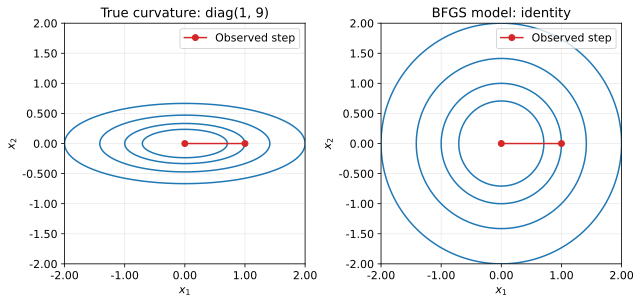

In [7]:
D = np.diag([1, 9])
s = np.array([-1, 0], dtype=float)
partial_H, _ = inverse_bfgs(np.eye(2), s, D @ s)
pprint({"H_after_one_step": partial_H, "true_inverse": np.linalg.solve(D, np.eye(2))})
display(Math(r"\mathbf{H}_1=\begin{bmatrix}1&0\\0&1\end{bmatrix},"
             r"\qquad\mathbf{D}^{-1}=\begin{bmatrix}1&0\\0&1/9\end{bmatrix}"))

u, v = np.meshgrid(np.linspace(-2, 2, 200), np.linspace(-2, 2, 200))
fig, axes = plt.subplots(1, 2, figsize=(8.80, 4.20), layout="constrained")
for ax, z, title in zip(axes, [(u**2 + 9*v**2)/2, (u**2 + v**2)/2],
                        ["True curvature: diag(1, 9)", "BFGS model: identity"]):
    ax.contour(u, v, z, levels=[1/4, 1/2, 1, 2], colors="tab:blue")
    ax.plot([1, 0], [0, 0], "o-", color="tab:red", label="Observed step")
    ax.set(xlabel="$x_1$", ylabel="$x_2$", title=title, aspect="equal")
save_figure(fig, "04_unobserved_direction.svg")

## 6. Hessianが変化する関数で確かめる

Rosenbrock関数を使う。勾配は連鎖律で計算できる。

$$
\begin{aligned}
f(\mathbf{x})&=(1-x_1)^2+100(x_2-x_1^2)^2,\\
\frac{\partial f}{\partial x_1}
&=-2(1-x_1)+200(x_2-x_1^2)(-2x_1)\\
&=2(x_1-1)-400x_1(x_2-x_1^2),\\
\frac{\partial f}{\partial x_2}&=200(x_2-x_1^2).
\end{aligned}
$$

最小点は$\mathbf{x}_*=(1,1)^\top$である。初期点を$(-1.20,1.00)^\top$とし、関数値と勾配だけをBFGSに渡す。図5は細長く曲がった谷に沿った移動を示す。

{'gradient_norm': '2.87e-10',
 'iterations': 35,
 'skipped_updates': 0,
 'success': True,
 'x': array([1.00, 1.00])}


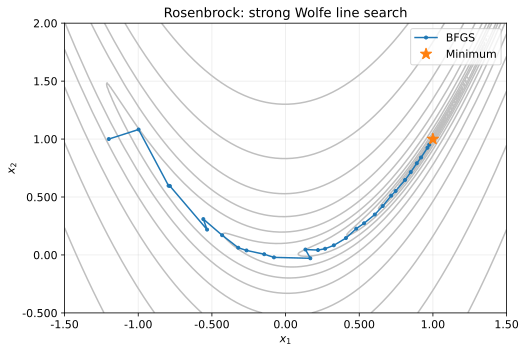

In [8]:
def rosenbrock(x):
    return (1 - x[0])**2 + 100 * (x[1] - x[0]**2)**2


def rosenbrock_grad(x):
    a, b = x
    return np.array([2*(a - 1) - 400*a*(b - a**2), 200*(b - a**2)])


rosen = bfgs_trace(rosenbrock, rosenbrock_grad, [-1.20, 1.00])
pprint({"success": rosen["success"], "iterations": len(rosen["x"]) - 1,
        "x": rosen["x"][-1],
        "gradient_norm": f"{np.linalg.norm(rosenbrock_grad(rosen['x'][-1])):#.3g}",
        "skipped_updates": int(np.count_nonzero(~rosen["updated"]))})

u, v = np.meshgrid(np.linspace(-1.50, 1.50, 240), np.linspace(-0.500, 2, 240))
fig, ax = plt.subplots(figsize=(7.20, 4.80), layout="constrained")
ax.contour(u, v, (1-u)**2 + 100*(v-u**2)**2, levels=np.logspace(-2, 3, 14), colors="0.750")
ax.plot(rosen["x"][:, 0], rosen["x"][:, 1], "o-", markersize=3, label="BFGS")
ax.plot(1, 1, "*", markersize=12, label="Minimum")
ax.set(xlabel="$x_1$", ylabel="$x_2$", title="Rosenbrock: strong Wolfe line search")
save_figure(fig, "05_rosenbrock_path.svg")

検算用にだけ真のHessianを用意する。これは最適化の処理には渡さない。

$$
\begin{aligned}
\frac{\partial^2f}{\partial x_1^2}
&=2-400(x_2-x_1^2)+800x_1^2=2-400x_2+1200x_1^2,\\
\frac{\partial^2f}{\partial x_2\partial x_1}&=-400x_1,
\qquad \frac{\partial^2f}{\partial x_2^2}=200,\\
\nabla^2f(\mathbf{x})
&=\begin{bmatrix}2-400x_2+1200x_1^2&-400x_1\\-400x_1&200\end{bmatrix}.
\end{aligned}
$$

図6では、$\mathbf{B}_k=\mathbf{H}_k^{-1}$とその点の真のHessianの差をFrobeniusノルムで測る。

$$
e_k=\frac{\|\mathbf{B}_k-\nabla^2f(\mathbf{x}_k)\|_F}
{\|\nabla^2f(\mathbf{x}_k)\|_F},
\qquad
r_k=\frac{\|\mathbf{H}_{k+1}\mathbf{y}_k-\mathbf{s}_k\|_2}{\|\mathbf{s}_k\|_2}.
$$

勾配ノルム、行列全体の誤差$e_k$、セカント残差$r_k$は異なる量である。$r_k$が小さくても$e_k$は0とは限らず、単調に減るとも限らない。対数軸では0を表示できないため、図3と図6の値は表示時だけ$1.00\times10^{-16}$を下限にする。

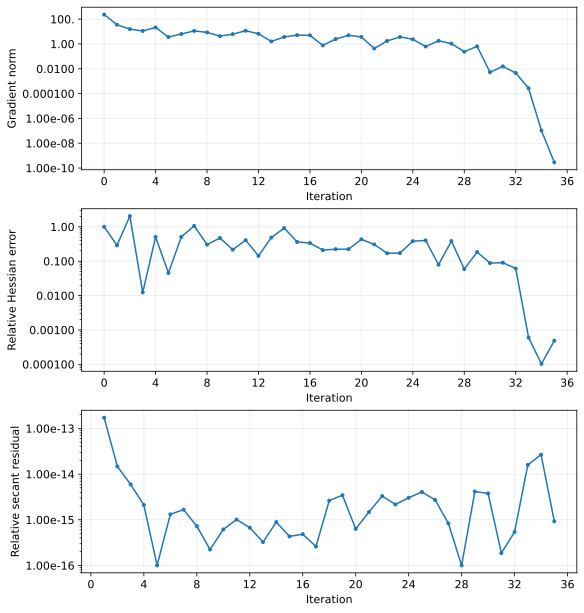

{'final_Hessian_error': '0.000484',
 'max_secant_residual': '1.72e-13',
 'smallest_eigenvalue_of_H': '0.000461'}


In [9]:
def rosenbrock_hessian(x):
    a, b = x
    return np.array([[2 - 400*b + 1200*a*a, -400*a], [-400*a, 200]])


grad_norm = np.array([np.linalg.norm(rosenbrock_grad(x)) for x in rosen["x"]])
errors = []
for x, H in zip(rosen["x"], rosen["H"]):
    B = np.linalg.solve(H, np.eye(2))  # 診断のためだけに逆行列を求める。
    G = rosenbrock_hessian(x)
    errors.append(np.linalg.norm(B - G) / np.linalg.norm(G))

fig, axes = plt.subplots(3, 1, figsize=(8, 8.40), layout="constrained")
series = [(np.arange(len(grad_norm)), grad_norm, "Gradient norm"),
          (np.arange(len(errors)), errors, "Relative Hessian error"),
          (np.arange(1, len(rosen["x"])), rosen["residual"], "Relative secant residual")]
for ax, (indices, values, label) in zip(axes, series):
    ax.semilogy(indices, np.maximum(values, 1.00e-16), "o-", markersize=3)
    ax.set(xlabel="Iteration", ylabel=label)
save_figure(fig, "06_rosenbrock_diagnostics.svg")

# 収束と正定値性を、図の見た目とは別に確認する。
assert quad["success"] and rosen["success"]
assert np.linalg.norm(rosen["x"][-1] - np.ones(2)) < 1.00e-6
assert np.all(np.linalg.eigvalsh(rosen["H"]) > 0)
assert np.all(rosen["residual"][rosen["updated"]] < 1.00e-8)
pprint({"max_secant_residual": f"{np.max(rosen['residual']):#.3g}",
        "final_Hessian_error": f"{errors[-1]:#.3g}",
        "smallest_eigenvalue_of_H": f"{np.min(np.linalg.eigvalsh(rosen['H'])):#.3g}"})

### SciPyのBFGSでも実行する

実用時は `minimize` に `method="BFGS"` と勾配 `jac` を渡せる。勾配を省略すると数値差分で推定されるため、「Hessian不要」は「微分情報不要」という意味ではない。[SciPy公式資料](https://docs.scipy.org/doc/scipy/reference/optimize.minimize-bfgs.html)

返り値の `hess_inv` は逆Hessianの近似である。自作実装とは直線探索などの詳細が異なるため、反復回数や最終行列が一致する必要はない。

In [10]:
result = minimize(rosenbrock, [-1.20, 1.00], jac=rosenbrock_grad, method="BFGS",
                  options={"gtol": 1.00e-8, "norm": 2, "maxiter": 200})
pprint({"success": bool(result.success), "message": str(result.message),
        "iterations": int(result.nit), "x": result.x,
        "gradient_norm": f"{np.linalg.norm(result.jac):#.3g}",
        "hess_inv": result.hess_inv})
assert result.success
assert np.linalg.norm(result.x - rosen["x"][-1]) < 1.00e-6

{'gradient_norm': '1.62e-11',
 'hess_inv': array([[0.501, 1.00],
       [1.00, 2.01]]),
 'iterations': 34,
 'message': 'Optimization terminated successfully.',
 'success': True,
 'x': array([1.00, 1.00])}


## 結論

この記事では、BFGSが勾配差と移動量の関係を使い、探索方向を決めるHessianまたは逆Hessianの近似を更新する仕組みを確認した。

セカント条件が合わせるのは、観測した方向での行列の作用である。真のHessianの全成分が復元されることや、その誤差が毎回減ることを意味しない。正の曲率と正定値性を保つことで降下方向を作り、歩幅は直線探索で決める。

BFGSは二階微分と毎回の逆行列計算を避ける一方、密行列に$O(n^2)$のメモリを使う。変数が多い場合には、少数の移動量と勾配差を保持するL-BFGSが選択肢になる。

参考文献として、更新式と収束条件はYudong Chenの[講義資料「Quasi-Newton: The BFGS and SR1 Methods」](https://pages.cs.wisc.edu/~yudongchen/cs726_sp23/Lecture_22_BFGS_SR1.pdf)、APIの詳細は本文中のSciPy公式資料を参照した。